# Waveguide bandwidth scan

The retained energies satisfy Omega_min = max(0, center - width), Omega_max = center + width. Once the lower edge reaches zero, the window is no longer symmetric around the chosen center. The horizontal axis shows the actual half-width (Omega_max - Omega_min)/2. RUN_SIMULATIONS=False reads the supplied results; True recomputes them.

**Setup:** from the repository root, run `conda env create -f environment.yml` then `conda activate single-photon-renorm`, then `jupyter lab`. Select that Python environment as the kernel. The first cell also supports running directly from the checkout.

**How to use:** run cells from top to bottom. Parameters are grouped before the simulation or plotting cells. Figures display inline; `SAVE_FIGURES=False` prevents overwriting exported PDFs. Units: ħ = c = 1. See `guide_utilisation.pdf` at the repository root for notation and the calibration workflow.


In [1]:
RUN_SIMULATIONS = False  # True recomputes the selected scan and writes its CSVs.
SAVE_FIGURES = True  # Set True to export the figures to results/fig.

# Run from the repository root or any of its subdirectories.
import sys
from pathlib import Path
project_root = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                     if (p / "src" / "experiment.py").is_file()), None)
if project_root is None:
    raise FileNotFoundError("Open Jupyter inside the single_photon_code checkout; see README.md.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
benchmark_root = project_root / "waveguide_model"
setup_root = project_root / "2d_setup"

#General imports
resol = 300
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import MultipleLocator, FuncFormatter

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "axes.linewidth": 0.7,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.direction": "in",
    "ytick.direction": "in",

    # Lines / markers
    "lines.linewidth": 1.0,
    "lines.markersize": 4,

})

import numpy as np
pi = np.pi


#Local imports
from waveguide_model.scripts_experiments.reflection_vs_bandwidth import run_reflection_vs_bandwidth


<h1> Execute the experiment </h1>

Prepare the parameters

In [2]:
#Physical parameters
Omega_A = 10*pi
gamma_A = pi

L = 100
param_cavity_physical = {'Omega_A': Omega_A, 'gamma_A': gamma_A, 'L': L}

param_time_evol = {'T': 50, 'dt': 0.01}


#Different photon momenta
p0_tab = [10*pi, 9.75*pi, 9.5*pi]

#Prepare ir_cutoff and uv_cutoff arrays for each experiment
nb_pts_bandwidth = 30
ir_cutoff_tab_list = []
uv_cutoff_tab_list = []


central_momenta = [10*pi, 8*pi, 6*pi, 4*pi]
for i in range(4):
    bandwidth_tab = np.linspace(pi, 40*pi, nb_pts_bandwidth)
    ir_cutoff_tab_list.append(np.maximum(0., central_momenta[i] - bandwidth_tab))
    uv_cutoff_tab_list.append(central_momenta[i] + bandwidth_tab)


Run all the experiments

In [3]:
if RUN_SIMULATIONS:
    correction = False

    for i in range(4):
        for j in range(3):
            print(f"Experiment with cutoff center {central_momenta[i]/pi}*pi and central momentum {p0_tab[j]/pi}*pi")
            param_photon = {'p_init': p0_tab[j], 'sigma_p': 0.05*np.pi, 'x_init': -25}

            _, _, _ = run_reflection_vs_bandwidth(param_photon, param_cavity_physical, param_time_evol, ir_cutoff_tab_list[i], uv_cutoff_tab_list[i],
                                                  index_experiment=i+1,
                                                  index_p0=j+1,
                                                  correction=correction)
else:
    print("Using the existing CSV results; scan skipped.")


Using the existing CSV results; scan skipped.


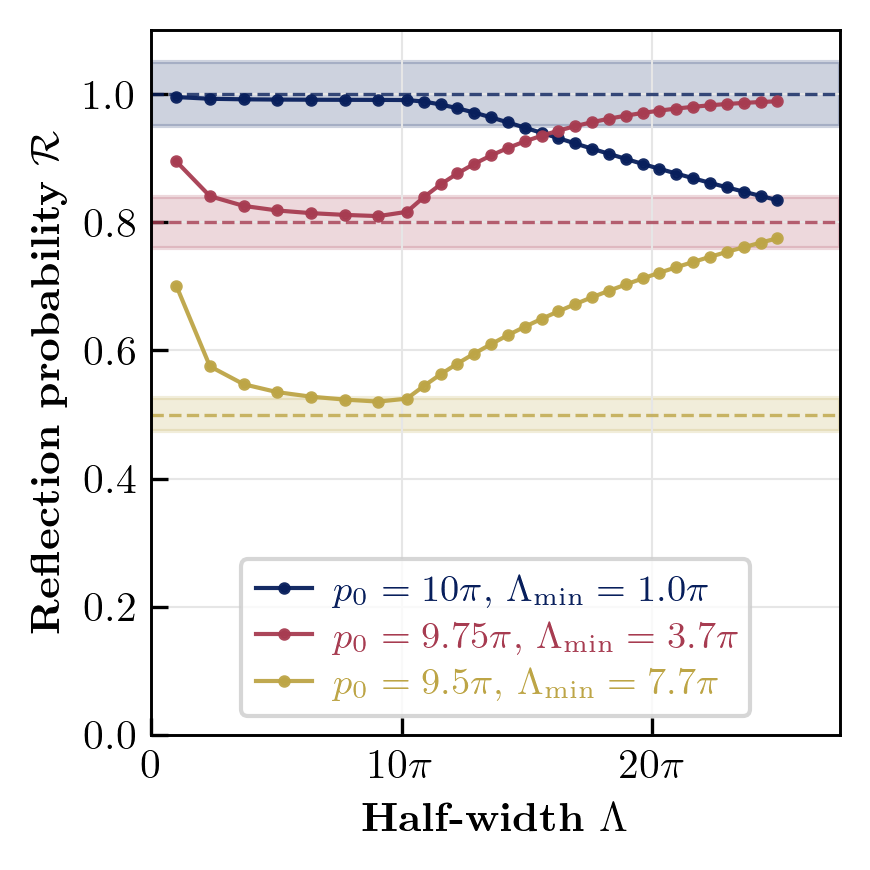

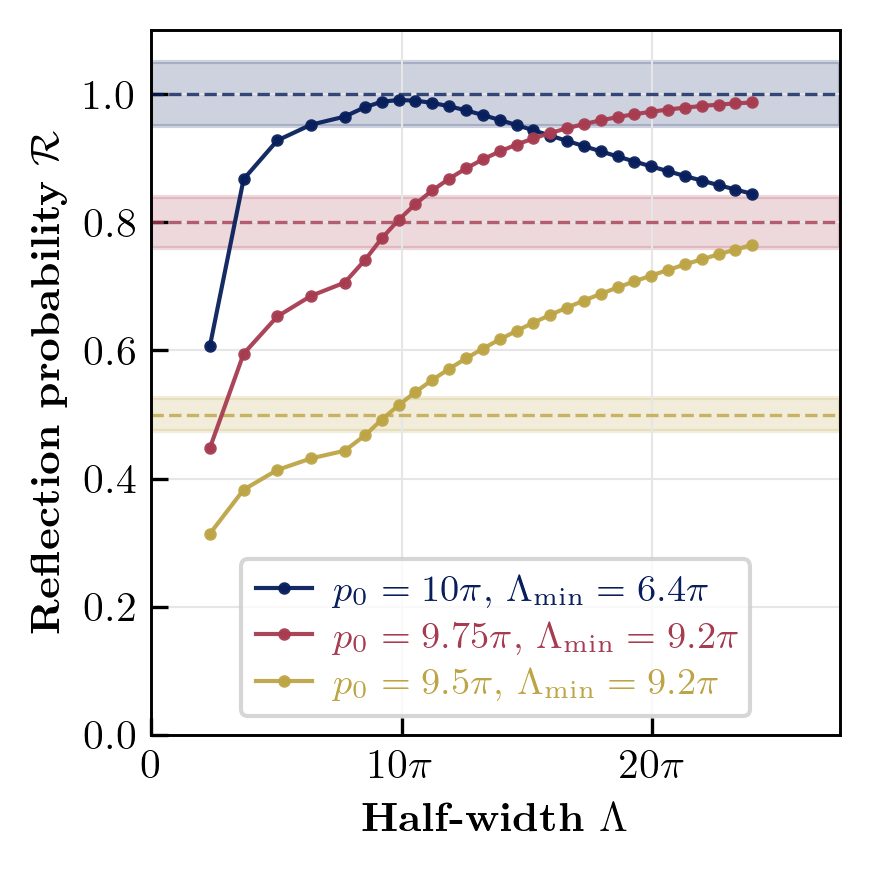

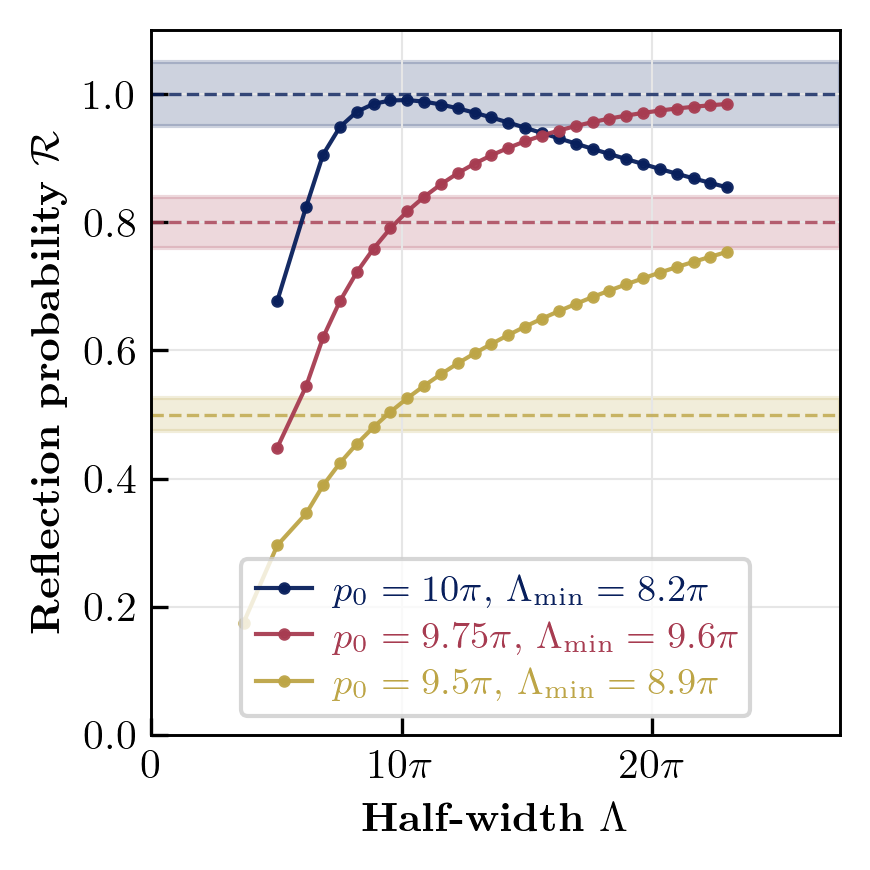

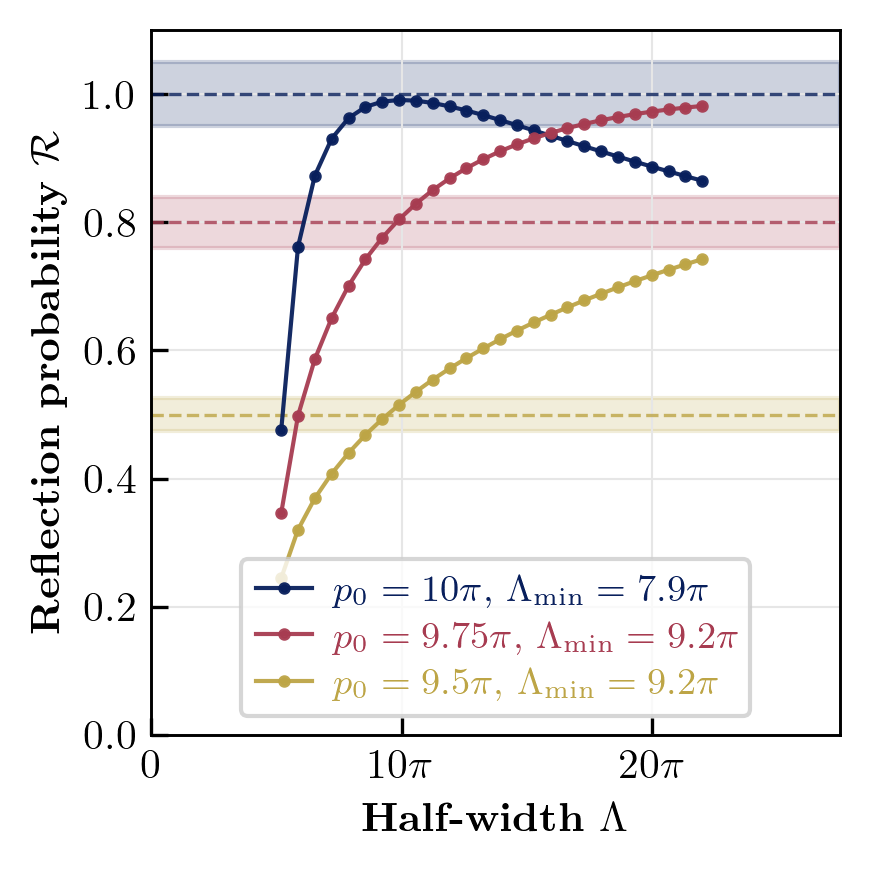

In [4]:
index_experiment_to_plot = [1,2,3,4]  
correction = False
max_x = 1.1 * max(np.max((uv - ir) / 2)
                  for ir, uv in zip(ir_cutoff_tab_list, uv_cutoff_tab_list))
colors = ['#081f5c', '#a73c51', '#bda546']

for index_experiment in index_experiment_to_plot:

    #Prepare the figure
    fig, ax = plt.subplots(figsize=(3, 3), dpi=300)
    p0_labels = [r'$p_0 = 10\pi$,', r'$p_0 = 9.75\pi,$', r'$p_0 = 9.5\pi$,']

    # Charger les données
    for j in range(3):
        index_p0 = j+1

        if correction:
            data_file = benchmark_root / "results" / "csv_files" / f"reflection_vs_bandwidth/reflection_vs_bandwidth_omega{index_p0}_xp{index_experiment}_corrected.csv"
        else:
            data_file = benchmark_root / "results" / "csv_files" / f"reflection_vs_bandwidth/reflection_vs_bandwidth_omega{index_p0}_xp{index_experiment}_uncorrected.csv"


        df = pd.read_csv(data_file)
        reflection_tab = df['reflection_tab'].to_numpy()
        ir_cutoff_tab = df['ir_tab'].to_numpy()
        uv_cutoff_tab = df['uv_tab'].to_numpy()
        bandwidth_tab = (uv_cutoff_tab - ir_cutoff_tab)/2

        theoretical_val = (gamma_A/2)**2/((p0_tab[j] - Omega_A)**2 + (gamma_A/2)**2)
        relative_error_tab = np.abs(reflection_tab - theoretical_val)/theoretical_val

        #get the minimal bandwidth for which the relative error is below 5%
        bandwidth_ok = bandwidth_tab[relative_error_tab < 0.05]
        if len(bandwidth_ok) > 0:
            min_bandwidth = np.min(bandwidth_ok)
            legend_label = (
                f"{p0_labels[j]} "
                rf"$\Lambda_{{\rm min}} = {min_bandwidth/np.pi:.1f}\pi$"
            )
        else:
            legend_label = (
                f"{p0_labels[j]} "
                "5% threshold not reached"
            )

        ax.plot(bandwidth_tab,
                reflection_tab,
                marker='o',
                markersize=2,
                label=legend_label,
                color=colors[j],
                linewidth=1,
                alpha=0.95,
                zorder=3)

        ax.hlines(theoretical_val,
                  0,
                  max_x,
                  color=colors[j],
                  linestyle='--',
                  linewidth=0.8,
                  alpha=0.8,
                  zorder=2)

        ax.fill_between(x=np.linspace(0, max_x, 500),
                        y1=0.95*theoretical_val,
                        y2=1.05*theoretical_val,
                        color=colors[j],
                        alpha=0.2,
                        zorder=1)


        # Grille
        ax.grid(color='0.9', linestyle='-', linewidth=0.5)

        # Axes labels
        ax.set_xlabel(r'\textbf{Half-width} $\Lambda$', fontsize=11)
        ax.set_ylabel(r'\textbf{Reflection probability} $\mathcal{R}$', fontsize=11)

        # Tick styling
        ax.tick_params(axis='both', which='major', length=4, width=0.8, labelsize=9)
        ax.set_xlim([0, max_x])
        ax.set_ylim([0, 1.1])

        # Tick x en unités de π
        ax.xaxis.set_major_locator(MultipleLocator(10*np.pi))
        def pi_formatter(x, pos):
            n = x / np.pi
            if np.isclose(n, 0):
                return "0"
            elif np.isclose(n, 1):
                return r"$\pi$"
            else:
                return rf"${int(round(n))}\pi$"
        ax.xaxis.set_major_formatter(FuncFormatter(pi_formatter))

            #font size
        for item in [ax.xaxis.label, ax.yaxis.label]:
            item.set_fontsize(10)

        for item in (ax.get_xticklabels() + ax.get_yticklabels()):
            item.set_fontsize(10)


    # Légende en deux colonnes alignées: omega_q | RE
    legend = ax.legend(prop={'size': 9},
                       loc="lower center",
                       frameon=True,
                       handlelength=1.5,
                       handletextpad=0.5,
                       labelspacing=0.35)
    for text, color in zip(legend.get_texts(), colors):
        text.set_color(color)

    plt.tight_layout()
    file_name = f"reflection_vs_bandwidth_xp{index_experiment}_" + ('corrected' if correction else 'uncorrected')
    if SAVE_FIGURES:
        (benchmark_root / "results" / "fig" / "reflection_vs_bandwidth").mkdir(parents=True, exist_ok=True)
        plt.savefig(str(benchmark_root / "results" / "fig" / f"reflection_vs_bandwidth/{file_name}.pdf"), bbox_inches='tight', pad_inches=0.2)
    plt.show()
